In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
df = pd.read_csv('automobile_dataset.csv')
df.columns = df.columns.str.strip()

In [19]:
df.head()

,Make,Model,Year,Fuel_Type,Transmission,Engine_Size,Mileage,Horsepower,Torque,Owners,Accident_History,Service_History,Color,Body_Type,Drivetrain,Fuel_Efficiency,Location,Selling_Price
0,Mercedes-Benz,GLE,2024,Petrol,Automatic,2.3,100,186.0,196.0,1,0.0,NaN,Silver,SUV,AWD,30.0,IL,64140
1,Hyundai,Tucson,2008,Petrol,Automatic,2.3,387035,189.0,190.0,4,0.0,NaN,Blue,SUV,FWD,35.0,FL,500
2,Volkswagen,Golf,2021,Hybrid,NaN,1.9,46054,158.0,153.0,1,0.0,Partial Service,Gray,Hatchback,AWD,43.0,NY,16429
3,Chevrolet,Tahoe,2005,Petrol,NaN,2.2,141302,169.0,165.0,5,1.0,No Service,Blue,SUV,AWD,NaN,FL,2199
4,Toyota,Camry,2022,Petrol,Automatic,1.9,32813,149.0,141.0,1,0.0,Full Service,Brown,Sedan,FWD,38.0,CA,21792


---

## 4. Data Preprocessing

### 4.1 Memeriksa Missing Value dan Duplikasi Data

In [20]:
print("--- Jumlah Missing Value per Kolom ---")
print(df.isnull().sum())
print("\n--- Jumlah Duplikasi Data ---")
print(df.duplicated().sum())

--- Jumlah Missing Value per Kolom ---
Make                  0
Model                 0
Year                  0
Fuel_Type             0
Transmission        827
Engine_Size         844
Mileage               0
Horsepower          800
Torque              799
Owners                0
Accident_History    812
Service_History     855
Color               803
Body_Type             0
Drivetrain            0
Fuel_Efficiency     794
Location            782
Selling_Price         0
dtype: int64

--- Jumlah Duplikasi Data ---
0


### 4.2 Menghapus Kolom Make, Model, dan Location & Mengimputasi Kolom yang Memiliki Missing Value

In [ ]:
df = df.drop(columns=['Make', 'Model', 'Location'])

kolom_numerik = ['Engine_Size', 'Horsepower', 'Torque', 'Fuel_Efficiency', 'Accident_History']
for kol in kolom_numerik:
    df[kol] = pd.to_numeric(df[kol], errors='coerce')

df['Transmission'] = df['Transmission'].fillna(df['Transmission'].mode()[0])
df['Engine_Size'] = df['Engine_Size'].fillna(df['Engine_Size'].median())
df['Horsepower'] = df['Horsepower'].fillna(df['Horsepower'].median())
df['Torque'] = df['Torque'].fillna(df['Torque'].median())
df['Accident_History'] = df['Accident_History'].fillna(0) 
df['Service_History'] = df['Service_History'].fillna('No Service')
df['Color'] = df['Color'].fillna(df['Color'].mode()[0])
df['Fuel_Efficiency'] = df['Fuel_Efficiency'].fillna(df['Fuel_Efficiency'].median())

print("Total Missing Value setelah imputasi:", df.isnull().sum().sum())

Total Missing Value setelah imputasi: 0


### 4.3 Mengubah Teks Kategori Menjadi Angka Unik & Memisahkan Fitur Kategorikal pada Kolom Fuel_Type, Body_Type, dan Drivetrain

In [22]:
df['Transmission'] = pd.factorize(df['Transmission'])[0]
df['Service_History'] = pd.factorize(df['Service_History'])[0]
df['Color'] = pd.factorize(df['Color'])[0]

df = pd.get_dummies(df, columns=['Fuel_Type', 'Body_Type', 'Drivetrain'], drop_first=True)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5500 entries, 0 to 5499
Data columns (total 22 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Year                 5500 non-null   int64  
 1   Transmission         5500 non-null   int64  
 2   Engine_Size          5500 non-null   float64
 3   Mileage              5500 non-null   int64  
 4   Horsepower           5500 non-null   float64
 5   Torque               5500 non-null   float64
 6   Owners               5500 non-null   int64  
 7   Accident_History     5500 non-null   float64
 8   Service_History      5500 non-null   int64  
 9   Color                5500 non-null   int64  
 10  Fuel_Efficiency      5500 non-null   float64
 11  Selling_Price        5500 non-null   int64  
 12  Fuel_Type_Electric   5500 non-null   bool   
 13  Fuel_Type_Hybrid     5500 non-null   bool   
 14  Fuel_Type_Petrol     5500 non-null   bool   
 15  Body_Type_Hatchback  5500 non-null   bool   
 16 

### 4.4 Membuat Label Target Baru

In [23]:
conditions = [
    df['Selling_Price'] <= 5000,
    (df['Selling_Price'] > 5000) & (df['Selling_Price'] <= 20000),
    df['Selling_Price'] > 20000
]

choices = ['Low', 'Medium', 'High']

df['Price_Category'] = np.select(conditions, choices, default='')

print("--- Menampilkan 5 Data Teratas ---\n", df[['Selling_Price', 'Price_Category']].head())
print("\n --- Jumlah Frekuensi ---\n", df['Price_Category'].value_counts())

--- Menampilkan 5 Data Teratas ---
    Selling_Price Price_Category
0          64140           High
1            500            Low
2          16429         Medium
3           2199            Low
4          21792           High

 --- Jumlah Frekuensi ---
 Price_Category
Medium    2125
Low       2091
High      1284
Name: count, dtype: int64


### 4.5 Mendeteksi dan Menangani Outlier (IQR dan Z-Score)

In [24]:
Q1 = df['Selling_Price'].quantile(0.25)
Q3 = df['Selling_Price'].quantile(0.75)
IQR = Q3 - Q1
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier_awal = ((df['Selling_Price'] < batas_bawah) | (df['Selling_Price'] > batas_atas)).sum()
df['Selling_Price'] = np.clip(df['Selling_Price'], batas_bawah, batas_atas)
outlier_akhir = ((df['Selling_Price'] < batas_bawah) | (df['Selling_Price'] > batas_atas)).sum()

print(f"Outlier Awal: {outlier_awal} -> Sisa Outlier: {outlier_akhir}")


Outlier Awal: 144 -> Sisa Outlier: 0


### 4.6 Feature Scaling Menggunakan Standardization

In [25]:
features = ['Year', 'Engine_Size', 'Mileage', 'Horsepower', 'Torque', 'Owners', 'Fuel_Efficiency']

df[features] = df[features].fillna(df[features].median())

mean = df[features].mean()
std = df[features].std()
df[features] = (df[features] - mean) / std

print(df[features].describe())

               Year   Engine_Size       Mileage    Horsepower        Torque  \
count  5.500000e+03  5.500000e+03  5.500000e+03  5.500000e+03  5.500000e+03   
mean   1.476249e-14  3.533335e-16  1.162706e-17  2.596711e-16  1.408167e-16   
std    1.000000e+00  1.000000e+00  1.000000e+00  1.000000e+00  1.000000e+00   
min   -1.639796e+00 -3.145301e+00 -1.245709e+00 -1.929480e+00 -2.103160e+00   
25%   -9.489191e-01 -4.414429e-01 -8.210140e-01 -6.121931e-01 -5.983796e-01   
50%   -8.532327e-02 -5.517743e-02 -1.916306e-01 -1.860121e-01 -1.793269e-01   
75%    9.509918e-01  4.598432e-01  6.338851e-01  5.113748e-01  4.683001e-01   
max    1.641868e+00  4.193742e+00  4.596194e+00  4.598837e+00  4.868354e+00   

             Owners  Fuel_Efficiency  
count  5.500000e+03     5.500000e+03  
mean   6.911643e-17    -3.552714e-17  
std    1.000000e+00     1.000000e+00  
min   -1.143730e+00    -1.707704e+00  
25%   -1.143730e+00    -4.196857e-01  
50%   -3.624938e-01    -1.334595e-01  
75%    4.187428

### 4.7 Membagi Data Uji dan Data Latih (80%:20%)

In [26]:
X = df.drop(columns=['Selling_Price', 'Price_Category'])
y = df['Selling_Price']

print(f"Bentuk X : {X.shape[0]} baris, {X.shape[1]} kolom")
print(f"Bentuk Y : {len(y)} label")

np.random.seed(43)
index = np.random.permutation(len(X))
batas = int(0.8 * len(X))

X_train = X.iloc[index[:batas]]
X_test = X.iloc[index[batas:]]
y_train = y.iloc[index[:batas]]
y_test = y.iloc[index[batas:]]

print(f"Data Latih  : {len(X_train)} baris (80%)")
print(f"Data Uji    : {len(X_test)} baris (20%)")

Bentuk X : 5500 baris, 21 kolom
Bentuk Y : 5500 label
Data Latih  : 4400 baris (80%)
Data Uji    : 1100 baris (20%)


---

## 5. Modelling Multiple Linear Regression

### 5.1 Menambahkan Kolom Intercept

In [27]:
def tambah_kolom_bias(x):
    return np.c_[np.ones(x.shape[0]), x].astype(float)

X_train_b = tambah_kolom_bias(X_train)
X_test_b = tambah_kolom_bias(X_test)

y_train = pd.to_numeric(y_train, errors='coerce')
y_test = pd.to_numeric(y_test, errors='coerce')

### 5.2 Melakukan Pelatihan Model Menggunakan Normal Equation (OLS)

In [28]:
beta = np.linalg.inv(X_train_b.T @ X_train_b) @ X_train_b.T @ y_train

print("--- Hasil Pelatihan Model Multiple Linear Regression ---")
print(f"Intercept (Beta 0)      : {beta[0]:,.2f} USD")
print("-" * 50)

for index, koefisien in enumerate(beta[1:], start=1):
    print(f"Koefisien Fitur ke-{index}  : {koefisien:,.2f}")

--- Hasil Pelatihan Model Multiple Linear Regression ---
Intercept (Beta 0)      : 9,036.58 USD
--------------------------------------------------
Koefisien Fitur ke-1  : 8,058.77
Koefisien Fitur ke-2  : 1,572.49
Koefisien Fitur ke-3  : -153.67
Koefisien Fitur ke-4  : -2,112.06
Koefisien Fitur ke-5  : -284.64
Koefisien Fitur ke-6  : 318.74
Koefisien Fitur ke-7  : -119.98
Koefisien Fitur ke-8  : -1,916.75
Koefisien Fitur ke-9  : 536.41
Koefisien Fitur ke-10  : -7.33
Koefisien Fitur ke-11  : 209.94
Koefisien Fitur ke-12  : -1,850.39
Koefisien Fitur ke-13  : -89.95
Koefisien Fitur ke-14  : 223.71
Koefisien Fitur ke-15  : -1,606.74
Koefisien Fitur ke-16  : 4,724.55
Koefisien Fitur ke-17  : 2,371.32
Koefisien Fitur ke-18  : 2,749.06
Koefisien Fitur ke-19  : -326.44
Koefisien Fitur ke-20  : -660.43
Koefisien Fitur ke-21  : -471.52


### 5.3 Melakukan Prediksi pada Data Latih dan Data Uji & Menampilkan Tabel Perbandingan

In [29]:
y_pred_train = X_train_b @ beta
y_pred_test = X_test_b @ beta

tabel_hasil_prediksi = pd.DataFrame({'Harga Aktual (USD)': y_test.values[:5], 'Harga Prediksi (USD)': y_pred_test[:5]
})

print("\n--- Contoh 5 Prediksi Harga Mobil Bekas pada Data Uji ---")
print(tabel_hasil_prediksi.to_string(index=False, formatters={'Harga Aktual (USD)': '{:,.2f}'.format, 'Harga Prediksi (USD)': '{:,.2f}'.format
}))


--- Contoh 5 Prediksi Harga Mobil Bekas pada Data Uji ---
Harga Aktual (USD) Harga Prediksi (USD)
         20,357.00            18,877.96
         15,210.00            21,387.64
         26,219.00            27,629.79
         30,397.00            22,052.81
         45,786.62            27,710.80


---

## 6. Evaluation

### 6.1 Melakukan Evaluasi Menggunakan Matriks Regresi

In [30]:
r2 = 1 - (np.sum((y_test - y_pred_test) ** 2) / np.sum((y_test - np.mean(y_test)) ** 2))
mse = np.mean((y_test - y_pred_test) ** 2)
rmse = np.sqrt(mse)
mae = np.mean(np.abs(y_test - y_pred_test))

print("--- Hasil Evaluasi Model ---")
print(f"R-Squared   : {r2:.4f}")
print(f"MSE         : {mse:,.2f}")
print(f"RMSE        : {rmse:,.2f} USD")
print(f"MAE         : {mae:,.2f} USD")

--- Hasil Evaluasi Model ---
R-Squared   : 0.7089
MSE         : 44,206,775.74
RMSE        : 6,648.82 USD
MAE         : 5,194.47 USD


### 6.2 Menghitung Nilai Matriks Evaluasi dengan Membandingkan Nilai Aktual dan Nilai Prediksi pada Data Latih dan Data Uji

In [31]:
r2_train = 1 - (np.sum((y_train - y_pred_train) ** 2) / np.sum((y_train - np.mean(y_train)) ** 2))
mse_train = np.mean((y_train - y_pred_train) ** 2)
rmse_train = np.sqrt(mse_train)
mae_train = np.mean(np.abs(y_train - y_pred_train))

r2_test = 1 - (np.sum((y_test - y_pred_test) ** 2) / np.sum((y_test - np.mean(y_test)) ** 2))
mse_test = np.mean((y_test - y_pred_test) ** 2)
rmse_test = np.sqrt(mse_test)
mae_test = np.mean(np.abs(y_test - y_pred_test))

tabel_evaluasi = pd.DataFrame({
    'Metrik Evaluasi': ['R-Squared (R2)', 'MSE', 'RMSE (USD)', 'MAE (USD)'],
    'Data Latih': [r2_train, mse_train, rmse_train, mae_train],
    'Data Uji': [r2_test, mse_test, rmse_test, mae_test]
})

print("--- Perbandingan Evaluasi Model ---")
print(tabel_evaluasi.to_string(index=False, formatters={
    'Data Latih': lambda x: f"{x:,.4f}" if x < 1 else f"{x:,.2f}",
    'Data Uji': lambda x: f"{x:,.4f}" if x < 1 else f"{x:,.2f}"
}))

--- Perbandingan Evaluasi Model ---
Metrik Evaluasi    Data Latih      Data Uji
 R-Squared (R2)        0.7116        0.7089
            MSE 41,439,148.40 44,206,775.74
     RMSE (USD)      6,437.32      6,648.82
      MAE (USD)      5,060.55      5,194.47


### 6.3 Visualisasi Grafik Prediksi (Scatter Plot)

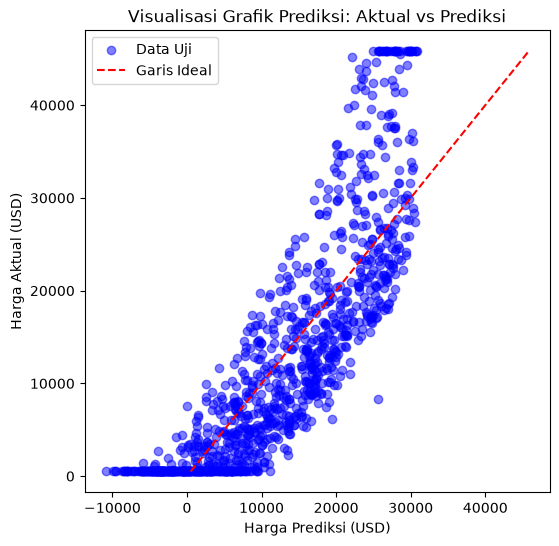

In [32]:
plt.figure(figsize=(6, 6))
plt.scatter(y_pred_test, y_test, color='blue', alpha=0.5, label='Data Uji')

plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--', label='Garis Ideal')

plt.xlabel('Harga Prediksi (USD)')
plt.ylabel('Harga Aktual (USD)')
plt.title('Visualisasi Grafik Prediksi: Aktual vs Prediksi')
plt.legend()

plt.show()

---

## 8. Conclusion

### 8.1 Kesimpulan Analisis dan Permodelan

Berdasarkan seluruh tahapan analisis data, *preprocessing*, pemodelan, hingga evaluasi yang telah dilakukan, dapat ditarik beberapa kesimpulan utama sebagai berikut:

1. Dataset awal terdiri dari **5.500 baris dan 18 kolom**. Pemeriksaan awal menunjukkan bahwa dataset bebas dari duplikasi data, namun ditemukan sejumlah nilai kosong (*missing value*) pada beberapa kolom spesifikasi yang berhasil diimputasi menggunakan metode median dan modus agar kualitas data tetap terjaga sebelum masuk ke tahap pemodelan. [Lihat Pemeriksaan Data Awal](#41-memeriksa-missing-value-dan-duplikasi-data)

2. Berdasarkan tahapan *preprocessing* dan *feature engineering*, kolom yang tidak relevan telah dihapus, teks kategori dikonversi menjadi angka dan dipisah menggunakan *one-hot encoding*, label target baru (`Price_Category`) dibentuk, pencilan (*outlier*) ditangani menggunakan metode IQR, serta fitur numerik distandarisasi sebelum dataset dibagi menjadi **4.400 data latih (80%)** dan **1.100 data uji (20%)**. [Lihat Transformasi dan Pembagian Data](#43-mengubah-teks-kategori-menjadi-angka-unik--memisahkan-fitur-kategorikal-kolom-fuel_type-body_type-dan-drivetrain)

3. Pengujian model menggunakan algoritma **Multiple Linear Regression (OLS)** yang dilatih melalui metode *Normal Equation* berhasil menghasilkan parameter intersep dan koefisien bobot yang optimal. Berdasarkan hasil evaluasi, model terbukti mampu memprediksi harga mobil bekas secara akurat dan konsisten dengan performa yang baik antara data latih dan data uji tanpa adanya indikasi *overfitting*. [Lihat Pelatihan dan Evaluasi Model](#52-melakukan-pelatihan-model-menggunakan-normal-equation-ols)